# 08. Aplicação em vídeo: da medida dos olhos ao alerta

Os notebooks anteriores tratam dos landmarks. Aqui olhamos para a segunda metade do projeto:
como transformar os pontos dos olhos numa decisão ao longo do tempo,
e por que escolhemos cada parâmetro do `app.py`.

1. O vídeo de teste e o que acontece nele
2. A medida dos olhos: EAR de 6 ou de 8 pontos, média ou mínimo dos dois olhos
3. A calibração e o limiar
4. A análise temporal: suavização, histerese e as três categorias de fechamento
5. Sensibilidade aos parâmetros
6. Os parâmetros escolhidos

Usamos um vídeo de 33 segundos gravado com a webcam de um notebook, a 30 quadros por segundo, sem
nada desenhado na imagem. O roteiro foi combinado antes da gravação, então sabemos onde estão os
fechamentos longos. O vídeo não é publicado; mostramos só as medidas.

In [1]:
from collections import deque
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from torch import nn
from torch.nn import functional as F

plt.rcParams["figure.dpi"] = 90
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
VIDEO = ROOT.parent / "videos" / "teste_webcam.mov"
WEIGHTS = ROOT / "weights" / "modelo.pt"
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
MIRROR = np.array((ROOT / "data" / "WFLW_annotations" / "Mirror98.txt").read_text().strip().split(","), dtype=int)
print(VIDEO.name, VIDEO.exists(), "|", WEIGHTS.relative_to(ROOT), "|", DEVICE)

teste_webcam.mov True | weights/modelo.pt | mps


## 1. O vídeo e as previsões

Para cada quadro: o YuNet acha a maior face, recortamos com a mesma regra do treino, o modelo
final prevê os 98 pontos (com a média da face espelhada) e guardamos os pontos dos olhos. O tempo
de cada quadro vem do índice do quadro dividido pela taxa do arquivo, o que deixa o resultado
independente da velocidade de processamento.

In [2]:
class LandmarkNet(nn.Module):
    def __init__(self, head_channels=256, num_deconv=3):
        super().__init__()
        resnet = torchvision.models.resnet18(weights=None)
        self.backbone = nn.Sequential(*list(resnet.children())[:-2])
        layers, c_in = [], 512
        for _ in range(num_deconv):
            layers += [nn.ConvTranspose2d(c_in, head_channels, 4, stride=2, padding=1, bias=False),
                       nn.BatchNorm2d(head_channels), nn.ReLU(inplace=True)]
            c_in = head_channels
        layers.append(nn.Conv2d(head_channels, 98, 1))
        self.head = nn.Sequential(*layers)
        self.stride = 32 // (2 ** num_deconv)

    def forward(self, x):
        logits = self.head(self.backbone(x))
        b, k, h, w = logits.shape
        prob = F.softmax(logits.reshape(b, k, -1).float(), -1).reshape(b, k, h, w)
        xs = torch.arange(w, device=x.device, dtype=prob.dtype)
        ys = torch.arange(h, device=x.device, dtype=prob.dtype)
        return torch.stack([(prob.sum(2) * xs).sum(-1), (prob.sum(3) * ys).sum(-1)], -1) * self.stride + (self.stride - 1) / 2


ckpt = torch.load(WEIGHTS, map_location="cpu", weights_only=False)
model = LandmarkNet(ckpt["config"]["model"]["head_channels"], ckpt["config"]["model"]["num_deconv"])
model.load_state_dict(ckpt["model"]); model.eval().to(DEVICE)
MEAN, STD = np.array([0.485, 0.456, 0.406], np.float32), np.array([0.229, 0.224, 0.225], np.float32)
yunet = cv2.FaceDetectorYN.create(str(ROOT / "models" / "face_detection_yunet_2023mar.onnx"), "", (320, 320), 0.6, 0.3, 5000)


def crop_matrix(box, size=256, margin=1.25):
    x0, y0, x1, y1 = box
    c = np.array([(x0 + x1) / 2, (y0 + y1) / 2])
    s = size / (margin * max(x1 - x0, y1 - y0))
    return np.array([[s, 0, size / 2 - s * c[0]], [0, s, size / 2 - s * c[1]]])


@torch.no_grad()
def landmarks(crop):
    x = torch.from_numpy(((crop / 255.0 - MEAN) / STD).transpose(2, 0, 1)[None].astype(np.float32)).to(DEVICE)
    p = model(x).float().cpu().numpy()
    q = model(torch.flip(x, dims=[3])).float().cpu().numpy()
    q[..., 0] = 255 - q[..., 0]
    return ((p + q[:, MIRROR]) / 2)[0]


cap = cv2.VideoCapture(str(VIDEO))
FPS = cap.get(cv2.CAP_PROP_FPS)
times, points, faces = [], [], []
i = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    s = 640 / max(frame.shape[:2])
    small = cv2.resize(frame, None, fx=s, fy=s)
    yunet.setInputSize((small.shape[1], small.shape[0]))
    _, det = yunet.detect(small)
    times.append(i / FPS)
    if det is None:
        points.append(None); faces.append(False)
    else:
        f = max(det, key=lambda d: d[2] * d[3])[:4] / s
        crop = cv2.warpAffine(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB), crop_matrix([f[0], f[1], f[0] + f[2], f[1] + f[3]]), (256, 256))
        points.append(landmarks(crop)); faces.append(True)
    i += 1
t = np.array(times)
print(f"{i} quadros a {FPS:.1f} fps ({t[-1]:.1f} s) | sem face: {i - sum(faces)}")

992 quadros a 30.0 fps (33.0 s) | sem face: 1


O roteiro do vídeo, conferido quadro a quadro:

| Trecho | O que acontece |
|---|---|
| 0 a 3,5 s | olhos abertos, com algumas piscadas (é a calibração) |
| 3,8 a 6,3 s | **fechamento longo** de cerca de 2,5 s, de frente |
| 9 a 11 s | cabeça virada para o lado, olhos abertos |
| 12,8 a 15,1 s | **fechamento longo** de cerca de 2,3 s, com a cabeça virada |
| perto de 17 s | piscada de um olho só |
| resto | olhos abertos, piscadas e movimentos da cabeça |

Um bom sistema deve dar **exatamente dois alertas**, um em cada fechamento longo, e nenhum na
cabeça virada.

In [3]:
LONG = [(3.8, 6.3), (12.8, 15.1)]
TURN = (9.0, 11.0)
EAR6 = {"direito": (60, 61, 63, 64, 65, 67), "esquerdo": (72, 71, 69, 68, 75, 73)}
EAR8 = {"direito": (60, 64, [(61, 67), (62, 66), (63, 65)]), "esquerdo": (72, 68, [(71, 73), (70, 74), (69, 75)])}


def ear6(p, idx):
    p1, p2, p3, p4, p5, p6 = (p[i] for i in idx)
    return (np.linalg.norm(p2 - p6) + np.linalg.norm(p3 - p5)) / (2 * np.linalg.norm(p1 - p4))


def ear8(p, spec):
    a, b, pairs = spec
    return sum(np.linalg.norm(p[u] - p[v]) for u, v in pairs) / (3 * np.linalg.norm(p[a] - p[b]))


def series(fn, spec, combine):
    out = []
    for p in points:
        if p is None:
            out.append(np.nan); continue
        r, l = fn(p, spec["direito"]), fn(p, spec["esquerdo"])
        out.append({"média": (r + l) / 2, "mínimo": min(r, l), "direito": r, "esquerdo": l}[combine])
    return np.array(out)


raw = {"EAR6 média": series(ear6, EAR6, "média"), "EAR8 média": series(ear8, EAR8, "média"),
       "EAR6 mínimo": series(ear6, EAR6, "mínimo"),
       "EAR6 olho direito": series(ear6, EAR6, "direito"), "EAR6 olho esquerdo": series(ear6, EAR6, "esquerdo")}

## 2. A medida dos olhos

Há duas escolhas a fazer:

- **quais pontos usar:** o EAR clássico de 6 pontos (cantos e os pontos laterais das pálpebras)
  ou um EAR de 8 pontos, que usa os três pares verticais de cada olho;
- **como juntar os dois olhos:** a média, o menor valor, ou um olho só.

Para comparar, medimos a **separação** entre olho aberto e fechado: a diferença entre o EAR típico
aberto e o típico fechado, dividida pelo ruído do olho aberto (desvio padrão). Quanto maior, mais
fácil escolher um limiar que não erre.

In [4]:
closed = np.zeros_like(t, dtype=bool)
for a, b in LONG:
    closed |= (t > a + 0.15) & (t < b - 0.15)
opened = ((t > 0.9) & (t < 1.5)) | ((t > 6.8) & (t < 8.4)) | ((t > 18.7) & (t < 19.7)) | ((t > 29) & (t < 31))
rows = {}
for name, e in raw.items():
    o, c = e[opened & ~np.isnan(e)], e[closed & ~np.isnan(e)]
    rows[name] = {"aberto (mediana)": np.median(o), "fechado (mediana)": np.median(c),
                  "ruído aberto (dp)": o.std(), "separação": (np.median(o) - np.median(c)) / o.std()}
pd.DataFrame(rows).T.round(3)

,aberto (mediana),fechado (mediana),ruído aberto (dp),separação
EAR6 média,0.275,0.010,0.014,19.166
EAR8 média,0.309,0.011,0.015,19.306
EAR6 mínimo,0.269,0.009,0.015,17.811
EAR6 olho direito,0.277,0.009,0.016,16.993
EAR6 olho esquerdo,0.278,0.012,0.016,16.909


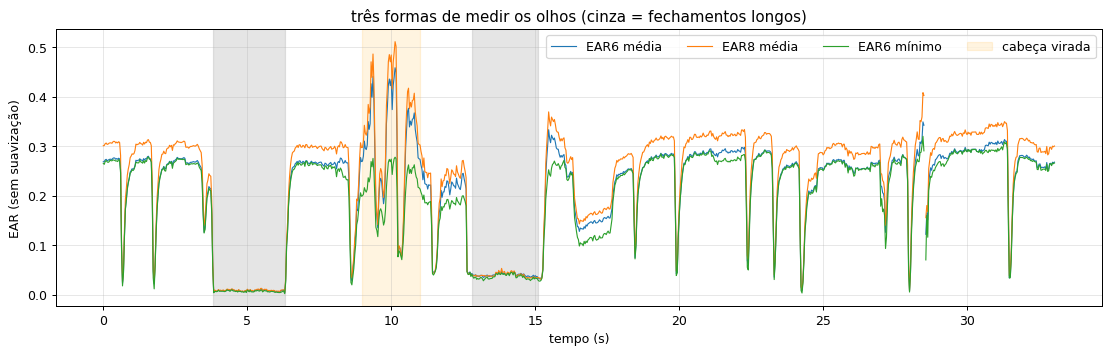

In [5]:
fig, ax = plt.subplots(figsize=(15, 4))
for name in ["EAR6 média", "EAR8 média", "EAR6 mínimo"]:
    ax.plot(t, raw[name], lw=0.9, label=name)
for a, b in LONG:
    ax.axvspan(a, b, color="gray", alpha=0.2)
ax.axvspan(*TURN, color="orange", alpha=0.12, label="cabeça virada")
ax.set_xlabel("tempo (s)"); ax.set_ylabel("EAR (sem suavização)"); ax.legend(ncol=4); ax.grid(alpha=0.3)
ax.set_title("três formas de medir os olhos (cinza = fechamentos longos)")
plt.show()

O EAR de 8 pontos e o de 6 se comportam de forma muito parecida (separação 19,3 contra 19,2). O
**mínimo** dos dois olhos e um olho sozinho separam pior (17 a 18), porque ficam com o ruído de um
olho só, e por definição reagem a qualquer olho que feche sozinho, como a piscada de um olho perto
de 17 s. Por isso preferimos a **média dos dois olhos**. Ficamos com o **EAR6 com média** como padrão
do `app.py` porque é a definição clássica (Soukupová e Čech) e a separação é praticamente a mesma;
o EAR8 fica disponível pela opção `--ear ear8`.

## 3. Calibração e limiar

O EAR de olho aberto muda de pessoa para pessoa e com a posição da câmera, então o limiar não é
um número fixo: nos primeiros 3 segundos com a face visível, medimos o EAR típico pela **mediana**
(que ignora as piscadas desse trecho) e o limiar de fechamento é uma **fração** dele.

calibração: 90 quadros | média 0.244 | mediana 0.270 (a média cai por causa das piscadas)


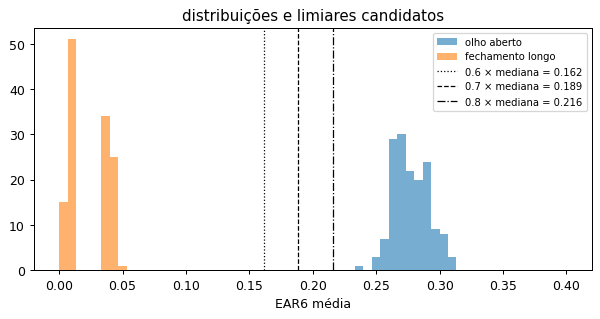

In [6]:
e = raw["EAR6 média"]
calib = e[(t < 3.0) & ~np.isnan(e)]
base = np.median(calib)
print(f"calibração: {len(calib)} quadros | média {calib.mean():.3f} | mediana {base:.3f} (a média cai por causa das piscadas)")
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(0, 0.4, 61)
ax.hist(e[opened], bins, alpha=0.6, label="olho aberto")
ax.hist(e[closed], bins, alpha=0.6, label="fechamento longo")
for frac, ls in [(0.6, ":"), (0.7, "--"), (0.8, "-.")]:
    ax.axvline(frac * base, c="k", ls=ls, lw=1, label=f"{frac} × mediana = {frac * base:.3f}")
ax.set_xlabel("EAR6 média"); ax.legend(fontsize=8); ax.set_title("distribuições e limiares candidatos")
plt.show()

Com o modelo final, olho aberto e olho fechado ficam bem separados: o EAR típico aberto é 0,27 e
o fechado fica perto de 0,01. Escolhemos **0,7 × mediana** para fechar (um valor intermediário) e **0,8 × mediana** para reabrir; a seção 5 mostra que essa escolha fica dentro da faixa
que não gera erros.

## 4. Análise temporal

A decisão quadro a quadro ("fechado se EAR < limiar") não basta: uma piscada também fecha o olho.
A máquina de estados do `app.py` faz o seguinte:

- **suavização:** média móvel de 3 quadros (0,1 s a 30 fps), que absorve um quadro isolado ruim sem
  apagar piscadas, que duram de 0,1 a 0,4 s;
- **histerese:** fecha abaixo de 0,7 × mediana e só reabre acima de 0,8 × mediana, para que o EAR
  oscilando perto do limiar não gere vários eventos seguidos;
- **classificação** de cada fechamento quando o olho reabre: **piscada** até 0,4 s (o limite
  superior de uma piscada espontânea), **fechamento curto** até 1,5 s e **fechamento longo** a partir
  de 1,5 s, que acende o **alerta** assim que a duração passa do limite, sem esperar o olho abrir.

A mesma lógica do `app.py`, aplicada à série de EAR do vídeo:

In [7]:
def run_monitor(e, t, close=0.7, reopen=0.8, smooth=3, blink_max=0.4, alert_s=1.5, calib_s=3.0):
    window, calib, calib_time, last = deque(maxlen=smooth), [], 0.0, None
    base, closed_since, events, alerts, state = None, None, [], [], []
    for ti, v in zip(t, e):
        if np.isnan(v):                       # sem face: mantém o estado
            state.append(closed_since is not None); continue
        window.append(v); s = np.mean(window)
        if base is None:
            if last is not None and ti - last < 0.5:
                calib_time += ti - last
            last = ti; calib.append(v)
            if calib_time >= calib_s and len(calib) >= 10:
                base = np.median(calib)
            state.append(False); continue
        if closed_since is None and s < close * base:
            closed_since, alerted = ti, False
        elif closed_since is not None and s > reopen * base:
            d = ti - closed_since
            events.append((closed_since, d, "piscada" if d <= blink_max else "curto" if d < alert_s else "longo"))
            closed_since = None
        if closed_since is not None and ti - closed_since >= alert_s and not alerted:
            alerts.append(round(ti, 2)); alerted = True
        state.append(closed_since is not None)
    return base, events, alerts, np.array(state)


base, events, alerts, state = run_monitor(raw["EAR6 média"], t)
kinds = pd.Series([k for _, _, k in events]).value_counts()
print(f"EAR típico {base:.3f} | limiar de fechamento {0.7 * base:.3f} | de reabertura {0.8 * base:.3f}")
print("eventos:", kinds.to_dict(), "| alertas acesos em (s):", alerts)
pd.DataFrame(events, columns=["início (s)", "duração (s)", "tipo"]).round(2)

EAR típico 0.269 | limiar de fechamento 0.189 | de reabertura 0.216
eventos: {'piscada': 12, 'curto': 3, 'longo': 2} | alertas acesos em (s): [np.float64(5.3), np.float64(14.13)]


,início (s),duração (s),tipo
0,3.50,0.23,piscada
1,3.80,2.73,longo
2,8.60,0.33,piscada
3,9.53,0.10,piscada
4,10.27,0.23,piscada
5,11.43,0.50,curto
6,12.63,2.77,longo
7,16.40,1.40,curto
8,18.47,0.17,piscada
9,19.90,0.20,piscada


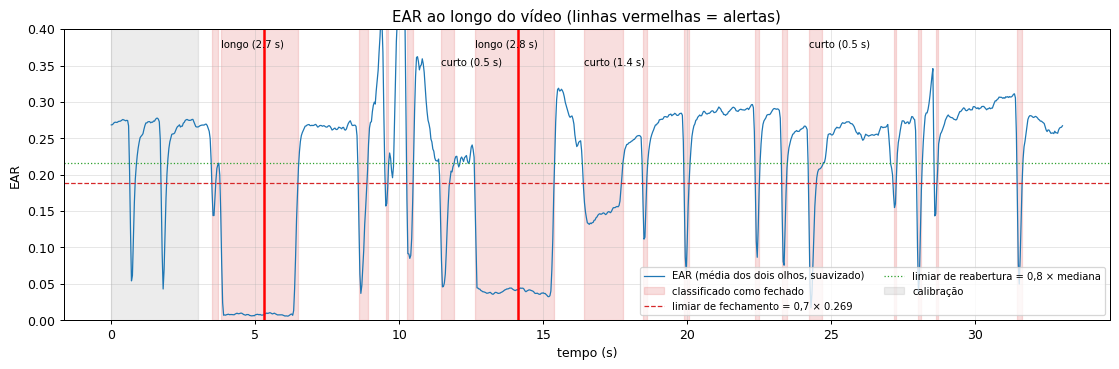

In [8]:
smooth = pd.Series(raw["EAR6 média"]).rolling(3, min_periods=1).mean().to_numpy()
fig, ax = plt.subplots(figsize=(15, 4.2))
ax.plot(t, smooth, lw=1, c="tab:blue", label="EAR (média dos dois olhos, suavizado)")
ax.fill_between(t, 0, 0.4, where=state, color="tab:red", alpha=0.15, label="classificado como fechado")
ax.axhline(0.7 * base, c="tab:red", ls="--", lw=1, label=f"limiar de fechamento = 0,7 × {base:.3f}")
ax.axhline(0.8 * base, c="tab:green", ls=":", lw=1, label="limiar de reabertura = 0,8 × mediana")
ax.axvspan(0, 3, color="gray", alpha=0.15, label="calibração")
for a in alerts:
    ax.axvline(a, c="red", lw=2)
for j, (st, d, k) in enumerate([ev for ev in events if ev[2] != "piscada"]):
    ax.annotate(f"{k} ({d:.1f} s)", (st, 0.375 - 0.025 * (j % 2)), fontsize=8)
ax.set_ylim(0, 0.4); ax.set_xlabel("tempo (s)"); ax.set_ylabel("EAR")
ax.legend(loc="lower right", fontsize=8, ncol=2); ax.grid(alpha=0.3)
ax.set_title("EAR ao longo do vídeo (linhas vermelhas = alertas)")
plt.show()

## 5. Sensibilidade aos parâmetros

Variando um parâmetro de cada vez em torno dos valores escolhidos, contamos quantos alertas
acontecem e se eles caem nos dois fechamentos longos do roteiro (alertas certos) ou fora deles
(falsos alertas).

In [9]:
def score(**kw):
    base, events, alerts, _ = run_monitor(raw["EAR6 média"], t, **kw)
    ok = sum(any(a - 0.1 <= x <= b + 0.1 for x in alerts) for a, b in LONG)
    false = sum(not any(a - 0.1 <= x <= b + 0.1 for a, b in LONG) for x in alerts)
    k = [kk for _, _, kk in events]
    return {"alertas certos (de 2)": ok, "falsos alertas": false,
            "piscadas": k.count("piscada"), "curtos": k.count("curto"), "longos": k.count("longo")}


grid = {}
for close in (0.5, 0.6, 0.7, 0.8):
    grid[("fração de fechamento", close)] = score(close=close, reopen=max(0.8, close + 0.1))
for smooth in (1, 3, 5, 9):
    grid[("média móvel (quadros)", smooth)] = score(smooth=smooth)
for alert_s in (1.0, 1.5, 2.0, 2.5):
    grid[("alerta a partir de (s)", alert_s)] = score(alert_s=alert_s)
pd.DataFrame(grid).T

alertas certos (de 2)  falsos alertas  piscadas  \
fração de fechamento   0.5                      2               0         8   
                       0.6                      2               0        12   
                       0.7                      2               0        12   
                       0.8                      2               1        10   
média móvel (quadros)  1.0                      2               0        13   
                       3.0                      2               0        12   
                       5.0                      2               0        11   
                       9.0                      2               0         8   
alerta a partir de (s) 1.0                      2               1        12   
                       1.5                      2               0        12   
                       2.0                      2               0        12   
                       2.5                      2               0        12   

                            curtos  longos  
fração de fechamento   0.5       3       2  
                       0.6       3       2  
                       0.7       3       2  
                       0.8       2       3  
média móvel (quadros)  1.0       3       2  
                       3.0       3       2  
                       5.0       3       2  
                       9.0       3       2  
alerta a partir de (s) 1.0       2       3  
                       1.5       3       2  
                       2.0       3       2  
                       2.5       3       2

O que dá para ler:

- a **fração de fechamento** funciona entre 0,6 e 0,7: os dois alertas certos e nenhum falso. Com
  0,8 o limiar fica perto demais do olho aberto e aparece um falso alerta; com 0,5 o sistema começa
  a perder piscadas (8 em vez de 12), porque piscadas rápidas não chegam tão baixo;
- a **média móvel** de 3 quadros mantém as piscadas; uma janela de 9 quadros (0,3 s) apaga piscadas
  rápidas (8 em vez de 12), e sem suavização aparece uma piscada a mais;
- o **tempo do alerta** entre 1,5 e 2,5 s dá o mesmo resultado neste vídeo, porque os dois
  fechamentos longos duram cerca de 2,7 s. Com 1,0 s, a piscada de um olho só (1,4 s, perto de
  16,4 s) já vira um falso alerta. Ficamos com 1,5 s: bem acima de uma piscada (no máximo 0,4 s) e
  dos fechamentos curtos, e o alerta ainda chega rápido.

## 6. Parâmetros escolhidos

| Parâmetro | Valor | Por quê |
|---|---|---|
| Medida | EAR de 6 pontos, média dos dois olhos | definição clássica; a média é menos ruidosa e não dispara com piscada de um olho nem com a cabeça virada |
| Calibração | mediana dos 3 primeiros segundos com face | robusta às piscadas da calibração |
| Fechar | EAR < 0,7 × mediana | dentro da faixa de 0,6 a 0,7 sem erros; 0,8 já gera falso alerta |
| Reabrir (histerese) | EAR > 0,8 × mediana | evita vários eventos quando o EAR oscila perto do limiar |
| Suavização | média móvel de 3 quadros | absorve um quadro ruim sem apagar piscadas |
| Piscada | até 0,4 s | limite superior de uma piscada espontânea |
| Alerta | fechamento a partir de 1,5 s | bem acima de uma piscada, rápido o bastante para avisar |
| Sem face | mantém o último estado e avisa na tela | uma cabeça que cai também é sinal de sonolência |

Todos esses valores são opções do `app.py` (`--ear`, `--close-ratio`, `--open-ratio`, `--smooth`,
`--blink-max`, `--alert-seconds`, `--calib-seconds`), com os padrões da tabela.

**Limitação:** um vídeo de uma pessoa só não basta para ajustar os parâmetros; ele serve para
conferir que os valores escolhidos pelos motivos acima funcionam. Óculos, pouca luz e olhar para
baixo devem ser testados no vídeo de demonstração.